# Week 5: Map your images

To start, save a copy to your Drive (File, then Save a copy in Drive), then run the cells in order. It runs on Colab's free CPU runtime. The outputs below are from the 56 museum chairs in the week 5 slides.

## 1. Setup

This loads CLIP, which takes about a minute.

In [1]:
import glob, io, os, sys, zipfile
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install umap-learn
import numpy as np, torch, umap
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from PIL import Image, ImageOps
from transformers import CLIPModel, CLIPProcessor

dev = "cuda" if torch.cuda.is_available() else "cpu"
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(dev).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
print("ready")

ready


## 2. Your images

With USE_EXAMPLE = True, it downloads the museum chairs. To use your own images, set it to False and run the cell again. It will ask for the zip you trained on, then for the images your model made (four is enough).

In [2]:
USE_EXAMPLE = True  # True: the 56 museum chairs from week 5. False: upload your own images.
TRAIN_DIR, MADE_DIR = "train", "made"

def unzip_upload(folder):
    """Ask for a zip of images (or several image files) and put them in `folder`."""
    from google.colab import files
    os.makedirs(folder, exist_ok=True)
    for name, data in files.upload().items():
        if name.lower().endswith(".zip"):
            zipfile.ZipFile(io.BytesIO(data)).extractall(folder)
        else:
            open(os.path.join(folder, name), "wb").write(data)

if USE_EXAMPLE:
    import csv, requests
    base = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/museum-chairs/"
    names = [r["file"] for r in csv.DictReader(io.StringIO(requests.get(base + "credits.csv", timeout=60).text))]
    for folder, files in [(TRAIN_DIR, names), (MADE_DIR, [f"made-{i}.jpg" for i in range(4)])]:
        os.makedirs(folder, exist_ok=True)
        for f in files:
            open(os.path.join(folder, f), "wb").write(requests.get(f"{base}{folder}/{f}", timeout=60).content)
    print("downloaded the example:", len(names), "training images and 4 made by the model")
else:
    print("Pick the zip you trained on:")
    unzip_upload(TRAIN_DIR)
    print("Pick the images your model made:")
    unzip_upload(MADE_DIR)

downloaded the example: 56 training images and 4 made by the model


## 3. Embed your images

In [3]:
EXT = (".jpg", ".jpeg", ".png", ".webp")
def images_in(folder):
    return sorted(p for p in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
                  if p.lower().endswith(EXT) and "__MACOSX" not in p)

def embed(paths):
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), 16):
            ims = [Image.open(p).convert("RGB") for p in paths[i:i + 16]]
            e = model.get_image_features(**proc(images=ims, return_tensors="pt").to(dev))
            if not torch.is_tensor(e):  # newer versions of transformers return an object
                e = e.image_embeds if getattr(e, "image_embeds", None) is not None else e.pooler_output
                if e.shape[-1] != model.config.projection_dim:
                    e = model.visual_projection(e)
            out.append(torch.nn.functional.normalize(e, dim=-1).cpu().numpy())
    return np.concatenate(out)

train, made = images_in(TRAIN_DIR), images_in(MADE_DIR)
E, N = embed(train), embed(made)
print(len(train), "training images,", len(made), "made by your model")

56 training images, 4 made by your model


## 4. Map

Your training images are faded, and the images your model made have a green border.

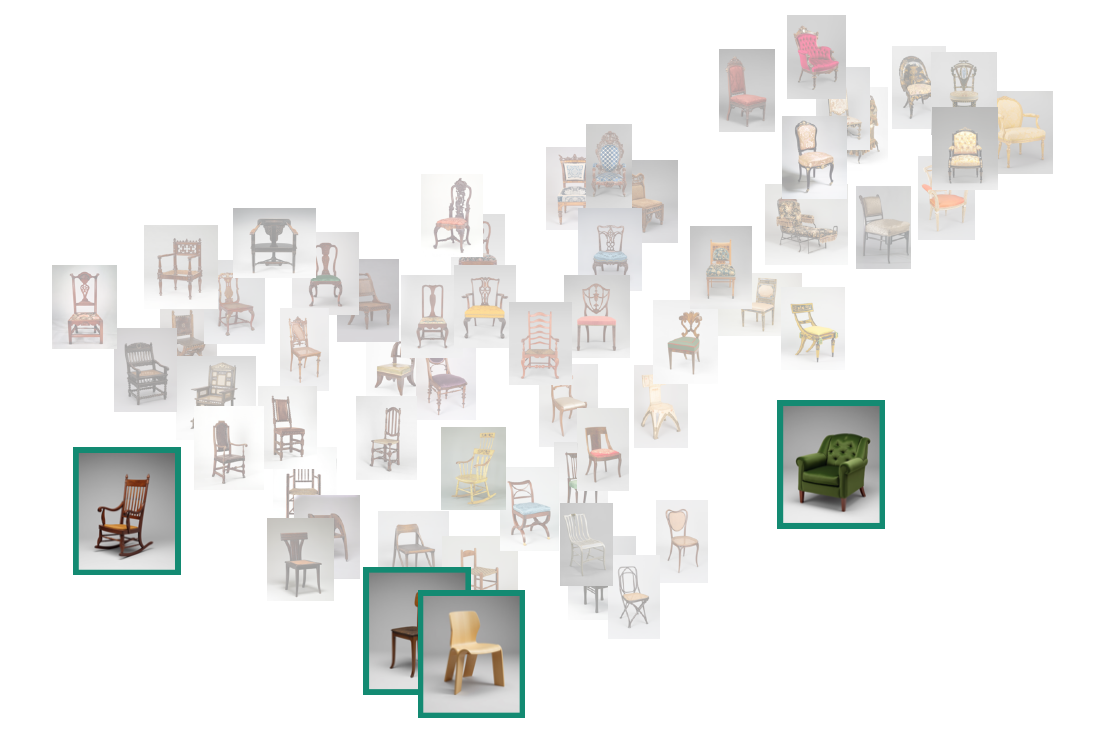

In [4]:
reducer = umap.UMAP(n_neighbors=min(15, len(train) - 1), min_dist=0.3, metric="cosine", random_state=0)
xy = reducer.fit_transform(E)
new_xy = reducer.transform(N)

def thumb(ax, path, x, y, size=0.5, faded=False, border=None):
    im = Image.open(path).convert("RGB")
    im.thumbnail((120, 120))
    if faded:
        im = Image.blend(im, Image.new("RGB", im.size, "white"), 0.6)
    if border:
        im = ImageOps.expand(im, border=6, fill=border)
    ax.add_artist(AnnotationBbox(OffsetImage(np.asarray(im), zoom=size), (x, y), frameon=False))

fig, ax = plt.subplots(figsize=(14, 9))
for (x, y), p in zip(xy, train):
    thumb(ax, p, x, y, faded=True)
for (x, y), p in zip(new_xy, made):
    thumb(ax, p, x, y, size=0.7, border="#138A72")
allxy = np.vstack([xy, new_xy])
pad = (allxy.max(0) - allxy.min(0)) * 0.08
ax.set_xlim(allxy[:, 0].min() - pad[0], allxy[:, 0].max() + pad[0])
ax.set_ylim(allxy[:, 1].min() - pad[1], allxy[:, 1].max() + pad[1])
ax.axis("off")
plt.savefig("map.jpg", dpi=120, bbox_inches="tight")
plt.show()

## 5. Closest training image

Under each image your model made, it shows the closest training image (found with DINOv2) and their similarity score. It first prints the median similarity between each training image and its closest other training image, which shows how similar your own images are to each other. If a pair scores near that number or above it, look at the two images and check whether your model copied one of yours.

Each training image and its closest other training image: median similarity 0.85


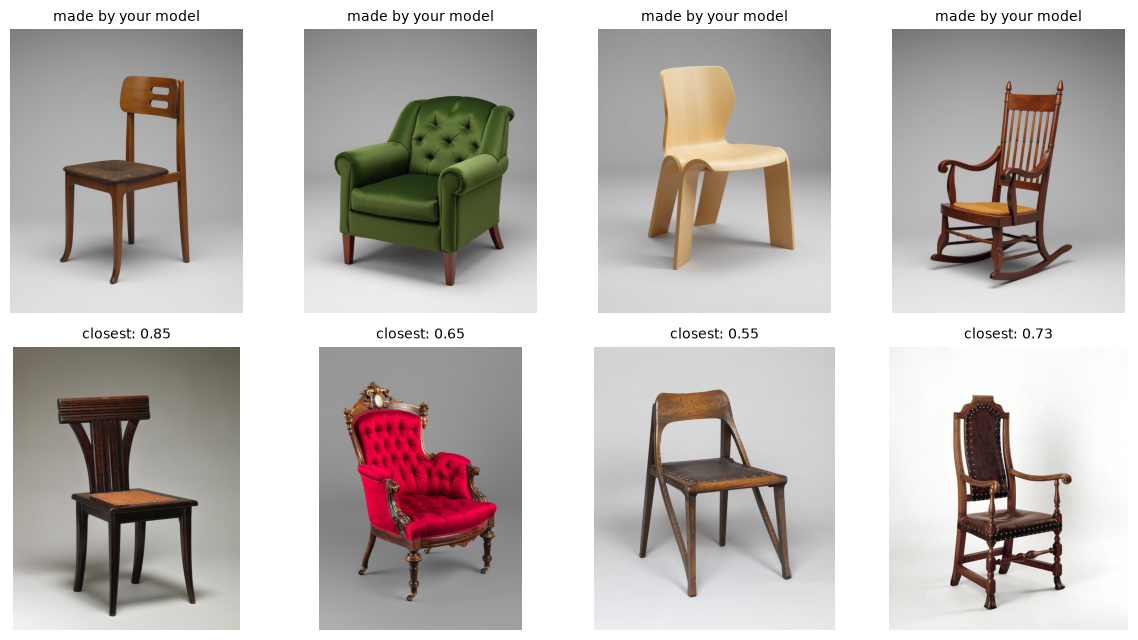

In [5]:
# DINOv2 is trained on images alone, and matches by how things look more closely than CLIP does.
from transformers import AutoImageProcessor, AutoModel
dproc = AutoImageProcessor.from_pretrained("facebook/dinov2-base")
dino = AutoModel.from_pretrained("facebook/dinov2-base").to(dev).eval()

def dino_embed(paths):
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), 8):
            ims = [Image.open(p).convert("RGB") for p in paths[i:i + 8]]
            e = dino(**dproc(images=ims, return_tensors="pt").to(dev)).pooler_output
            out.append(torch.nn.functional.normalize(e, dim=-1).cpu().numpy())
    return np.concatenate(out)

DT, DN = dino_embed(train), dino_embed(made)
S = DN @ DT.T
TT = DT @ DT.T
np.fill_diagonal(TT, -1)
print(f"Each training image and its closest other training image: median similarity {np.median(TT.max(1)):.2f}")
fig, axes = plt.subplots(2, len(made), figsize=(3 * len(made), 6.5), squeeze=False)
for i, p in enumerate(made):
    j = int(S[i].argmax())
    for row, (path, label) in enumerate([(p, "made by your model"), (train[j], f"closest: {S[i, j]:.2f}")]):
        axes[row, i].imshow(Image.open(path).convert("RGB"))
        axes[row, i].set_title(label, fontsize=10)
        axes[row, i].axis("off")
plt.tight_layout()
plt.savefig("closest.jpg", dpi=120)
plt.show()